# Caso 06: AulaViva — Cursos online: ¿Qué alumno se queda?
## Día 5 (Viernes): Que se Entienda y Cambie Algo (Visualización Ejecutiva y One-Pager para Comité)

**Objetivos del Día 5:**
1. **Traducir el hallazgo a decisiones ejecutivas (Pirámide Invertida):**
   - A quien decide (Elena Sanchís, CEO) se le entrega primero la **recomendación accionable**, luego **el porqué en una sola cifra** (`38 %` de las altas vs `15 %` del valor en `cupon`, frente a `12 %` de las altas y `24 %` del valor en `referido`), y después los **cuatro hallazgos** que lo sostienen.
2. **Construir las 4 figuras limpias con Seaborn (sin *chartjunk*, ejes desde cero, títulos que concluyen):**
   - **Gráfico 1 (Decide):** `dia_05_grafico_1_cuota_altas_vs_valor.png` — Cuota de Altas vs Cuota de Valor por canal.
   - **Gráfico 2 (Explica):** `dia_05_grafico_2_mecanismo_finalizacion_renovacion.png` — El mecanismo causal (Finalización, Renovación y LTV por canal).
   - **Gráfico 3 (Ilustra):** `dia_05_grafico_3_embudo_cupon_vs_referido.png` — El embudo del alumno de cada 100 altas (`cupon`: `100` $\rightarrow$ `9` $\rightarrow$ `18` $\rightarrow$ `42 €` vs `referido`: `100` $\rightarrow$ `44` $\rightarrow$ `71` $\rightarrow$ `210 €`).
   - **Gráfico 4 (Blinda):** `dia_05_grafico_4_control_confusion_categorias.png` — Control de confusión por categoría de curso (descarte de la hipótesis de Paula Rivas).
3. **Dejar preparadas las respuestas a las 4 preguntas del comité y el cierre del círculo (llevar la métrica a Looker).**


In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

CLEAN_DIR = os.path.join('data', 'clean')
REPORTS_DIR = 'reports'
os.makedirs(REPORTS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

con = duckdb.connect()
for nombre in ['canales', 'campanas', 'usuarios', 'suscripciones', 'pagos', 'matriculas', 'cursos']:
    pq_path = os.path.join(CLEAN_DIR, f"{nombre}.parquet").replace("\\", "/")
    con.execute(f"CREATE OR REPLACE VIEW {nombre} AS SELECT * FROM '{pq_path}'")

print("Datos limpios conectados en DuckDB.")


Datos limpios conectados en DuckDB.


### 1. Extracción de la Tabla Resumen Ejecutiva para las Figuras del Comité
Consolidamos en una sola consulta las métricas validadas durante la semana para alimentar los cuatro gráficos.


In [2]:
q_resumen = """
WITH altas AS (
    SELECT
        canal,
        COUNT(*) AS altas,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS cuota_altas_pct
    FROM usuarios
    GROUP BY canal
),
costes AS (
    SELECT canal, SUM(coste) AS coste_total
    FROM campanas
    GROUP BY canal
),
primeras_cuotas AS (
    SELECT
        u.canal,
        ROUND(SUM(p.importe), 0) AS ingreso_1a_cuota_eur
    FROM pagos p
    JOIN suscripciones s ON p.suscripcion_id = s.suscripcion_id
    JOIN usuarios u ON s.usuario_id = u.usuario_id
    WHERE p.importe_valido = TRUE AND p.tipo = 'alta'
    GROUP BY u.canal
),
aprendizaje AS (
    SELECT
        u.canal,
        COUNT(m.matricula_id) AS n_matriculas,
        ROUND(100.0 * SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) / COUNT(m.matricula_id), 1) AS finalizacion_pct
    FROM matriculas m
    JOIN usuarios u ON m.usuario_id = u.usuario_id
    GROUP BY u.canal
),
renovacion_usuario AS (
    SELECT
        u.usuario_id,
        u.canal,
        MAX(CASE WHEN p.tipo = 'renovacion' AND p.importe_valido = TRUE THEN 1 ELSE 0 END) AS renovo,
        COALESCE(SUM(CASE WHEN p.importe_valido = TRUE THEN p.importe ELSE 0 END), 0) AS gasto_alumno
    FROM usuarios u
    LEFT JOIN suscripciones s ON u.usuario_id = s.usuario_id
    LEFT JOIN pagos p ON s.suscripcion_id = p.suscripcion_id
    GROUP BY u.usuario_id, u.canal
),
valor_canal AS (
    SELECT
        canal,
        ROUND(100.0 * SUM(renovo) / COUNT(*), 1) AS renovacion_pct,
        ROUND(AVG(gasto_alumno), 2) AS ltv_eur,
        ROUND(SUM(gasto_alumno), 0) AS valor_total_eur,
        ROUND(100.0 * SUM(gasto_alumno) / SUM(SUM(gasto_alumno)) OVER (), 1) AS cuota_valor_pct
    FROM renovacion_usuario
    GROUP BY canal
)
SELECT
    a.canal,
    a.altas,
    a.cuota_altas_pct,
    ROUND(COALESCE(c.coste_total, 0) / a.altas, 0) AS cac_eur,
    pc.ingreso_1a_cuota_eur,
    ap.n_matriculas,
    ap.finalizacion_pct,
    v.renovacion_pct,
    v.ltv_eur,
    v.valor_total_eur,
    v.cuota_valor_pct
FROM altas a
LEFT JOIN costes c ON a.canal = c.canal
JOIN primeras_cuotas pc ON a.canal = pc.canal
JOIN aprendizaje ap ON a.canal = ap.canal
JOIN valor_canal v ON a.canal = v.canal
ORDER BY a.altas DESC
"""
df_resumen = con.execute(q_resumen).df()
df_resumen


,canal,altas,cuota_altas_pct,cac_eur,ingreso_1a_cuota_eur,n_matriculas,finalizacion_pct,renovacion_pct,ltv_eur,valor_total_eur,cuota_valor_pct
0,cupon,15200,38.0,6.0,278352.0,93905,9.0,17.9,41.83,635880.0,15.1
1,anuncios,9600,24.0,22.0,466855.0,59714,22.1,40.1,94.67,908799.0,21.6
2,seo,8000,20.0,0.0,379915.0,49419,30.9,54.2,128.13,1025059.0,24.4
3,referido,4800,12.0,10.0,230775.0,29705,44.0,71.0,209.98,1007902.0,24.0
4,empresas,2400,6.0,40.0,114296.0,14911,52.1,78.4,260.85,626034.0,14.9


### 2. Gráfico 1 (EL QUE DECIDE): Cuota de Altas vs. Cuota de Valor por Canal
* **Regla del fogonazo:** Una sola idea, ejes empezando en cero, colores con significado y título que enuncia la conclusión.


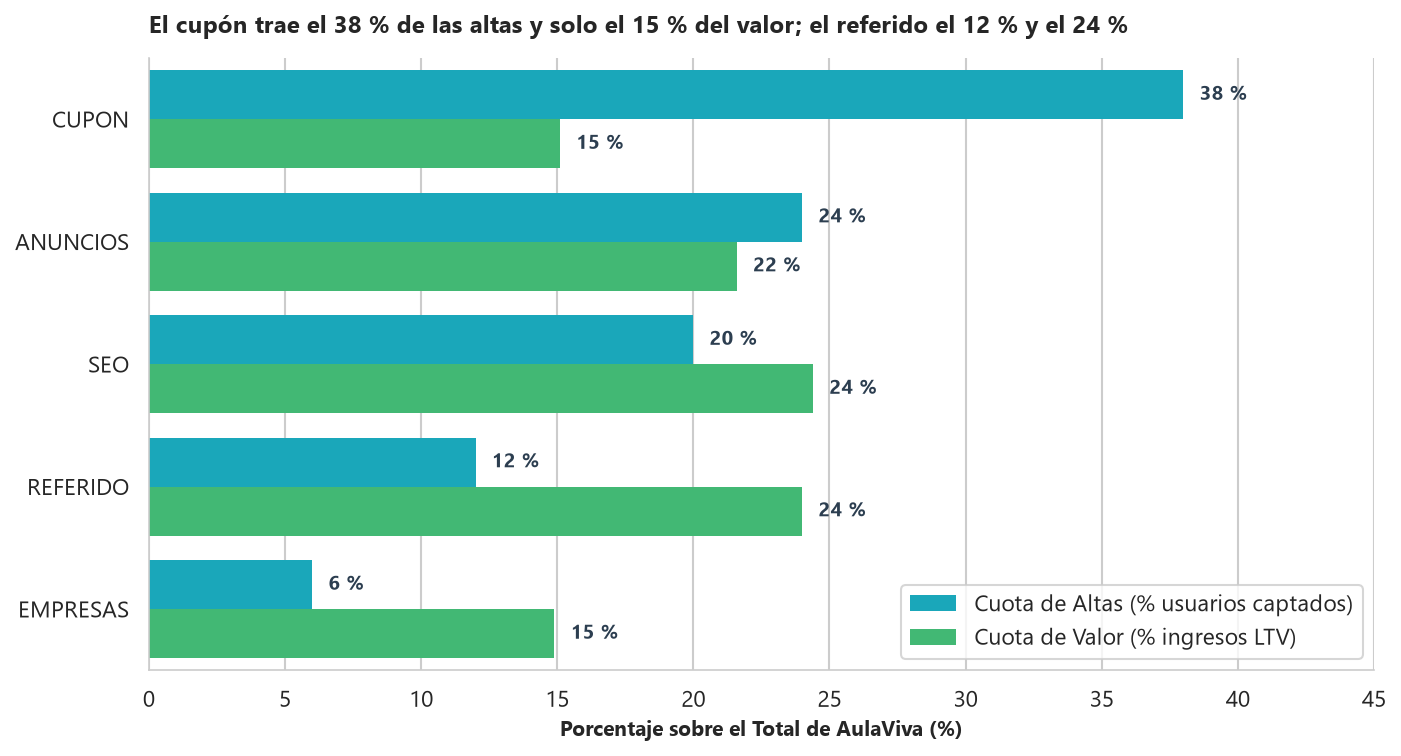

Guardado: reports\dia_05_grafico_1_cuota_altas_vs_valor.png


In [3]:
fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=150)

orden = ['cupon', 'anuncios', 'seo', 'referido', 'empresas']
df_g1 = df_resumen.set_index('canal').loc[orden].reset_index()

df_melt = df_g1.melt(
    id_vars='canal',
    value_vars=['cuota_altas_pct', 'cuota_valor_pct'],
    var_name='metrica',
    value_name='porcentaje'
)
df_melt['metrica'] = df_melt['metrica'].map({
    'cuota_altas_pct': 'Cuota de Altas (% usuarios captados)',
    'cuota_valor_pct': 'Cuota de Valor (% ingresos LTV)'
})
df_melt['canal_label'] = df_melt['canal'].str.upper()

palette_g1 = {
    'Cuota de Altas (% usuarios captados)': '#00bcd4',
    'Cuota de Valor (% ingresos LTV)': '#2ecc71'
}

sns.barplot(
    data=df_melt,
    x='porcentaje',
    y='canal_label',
    hue='metrica',
    palette=palette_g1,
    ax=ax,
    edgecolor='none'
)

for container in ax.containers:
    for bar in container:
        w = bar.get_width()
        ax.text(
            w + 0.6,
            bar.get_y() + bar.get_height() / 2,
            f"{w:.0f} %",
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#2c3e50'
        )

ax.set_xlim(0, 45)
ax.set_xlabel('Porcentaje sobre el Total de AulaViva (%)', fontsize=10, fontweight='bold')
ax.set_ylabel('')
ax.set_title('El cupón trae el 38 % de las altas y solo el 15 % del valor; el referido el 12 % y el 24 %', fontsize=11.5, fontweight='bold', loc='left', pad=12)
ax.legend(title='', loc='lower right', frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()

g1_path = os.path.join(REPORTS_DIR, 'dia_05_grafico_1_cuota_altas_vs_valor.png')
plt.savefig(g1_path, dpi=150)
plt.show()
print("Guardado:", g1_path)


### 3. Gráfico 2 (EL QUE EXPLICA): El Mecanismo Causal — Finalización, Renovación y LTV por Alumno
Enseña por qué el cupón aporta tan poco valor: quien no termina cursos (9 %) no renueva (18 %) y deja una quinta parte del dinero (42 € vs 210 € del referido).


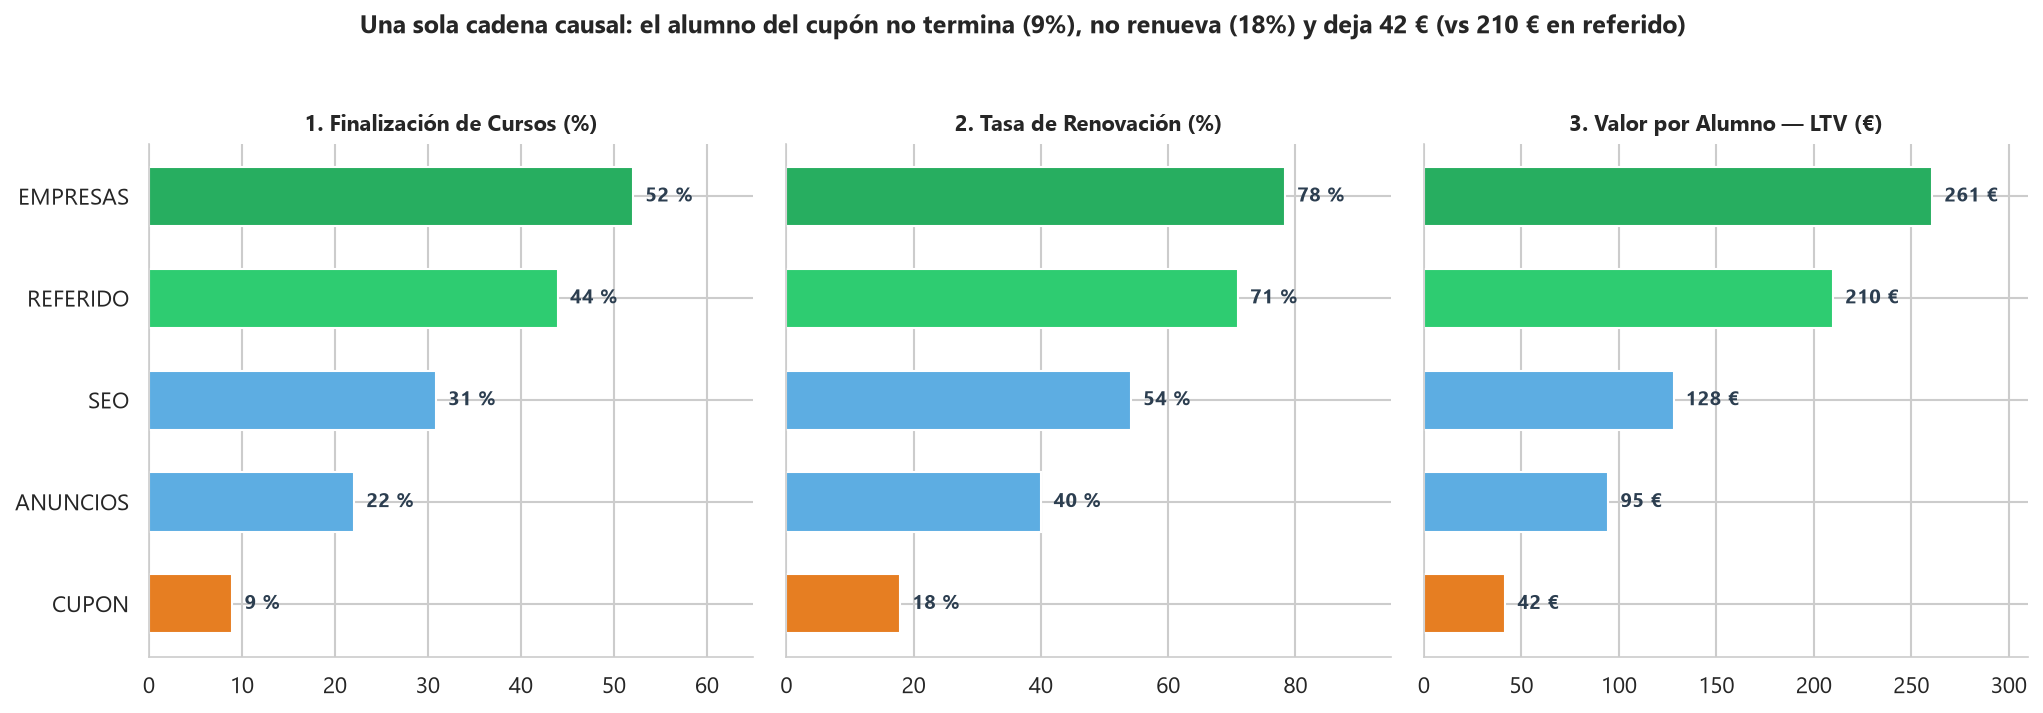

Guardado: reports\dia_05_grafico_2_mecanismo_finalizacion_renovacion.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.6), dpi=150, sharey=True)

df_g2 = df_resumen.sort_values('ltv_eur', ascending=True).reset_index(drop=True)
colores_g2 = ['#e67e22' if c == 'cupon' else ('#2ecc71' if c == 'referido' else ('#27ae60' if c == 'empresas' else '#5dade2')) for c in df_g2['canal']]

paneles = [
    ('finalizacion_pct', '1. Finalización de Cursos (%)', '%', 65),
    ('renovacion_pct', '2. Tasa de Renovación (%)', '%', 95),
    ('ltv_eur', '3. Valor por Alumno — LTV (€)', ' €', 310)
]

for ax, (col, titulo, suf, xmax) in zip(axes, paneles):
    bars = ax.barh(df_g2['canal'].str.upper(), df_g2[col], color=colores_g2, height=0.58)
    ax.set_xlim(0, xmax)
    ax.set_title(titulo, fontsize=10.5, fontweight='bold')
    sns.despine(ax=ax, top=True, right=True)
    for bar in bars:
        w = bar.get_width()
        txt = f"{w:.0f}{suf}" if col == 'ltv_eur' else f"{w:.0f} {suf}"
        ax.text(w + xmax * 0.02, bar.get_y() + bar.get_height()/2, txt, va='center', ha='left', fontsize=9.5, fontweight='bold', color='#2c3e50')

fig.suptitle('Una sola cadena causal: el alumno del cupón no termina (9%), no renueva (18%) y deja 42 € (vs 210 € en referido)', fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()

g2_path = os.path.join(REPORTS_DIR, 'dia_05_grafico_2_mecanismo_finalizacion_renovacion.png')
plt.savefig(g2_path, dpi=150, bbox_inches='tight')
plt.show()
print("Guardado:", g2_path)


### 4. Gráfico 3 (EL QUE ILUSTRA): El Embudo Enfrentado del Alumno (De cada 100 Altas, Cuánto Queda)
Compara cara a cara el recorrido de 100 alumnos captados por **Cupón** frente a 100 alumnos captados por **Referido**: el embudo del cupón se estrecha de golpe; el del referido aguanta hasta el final.


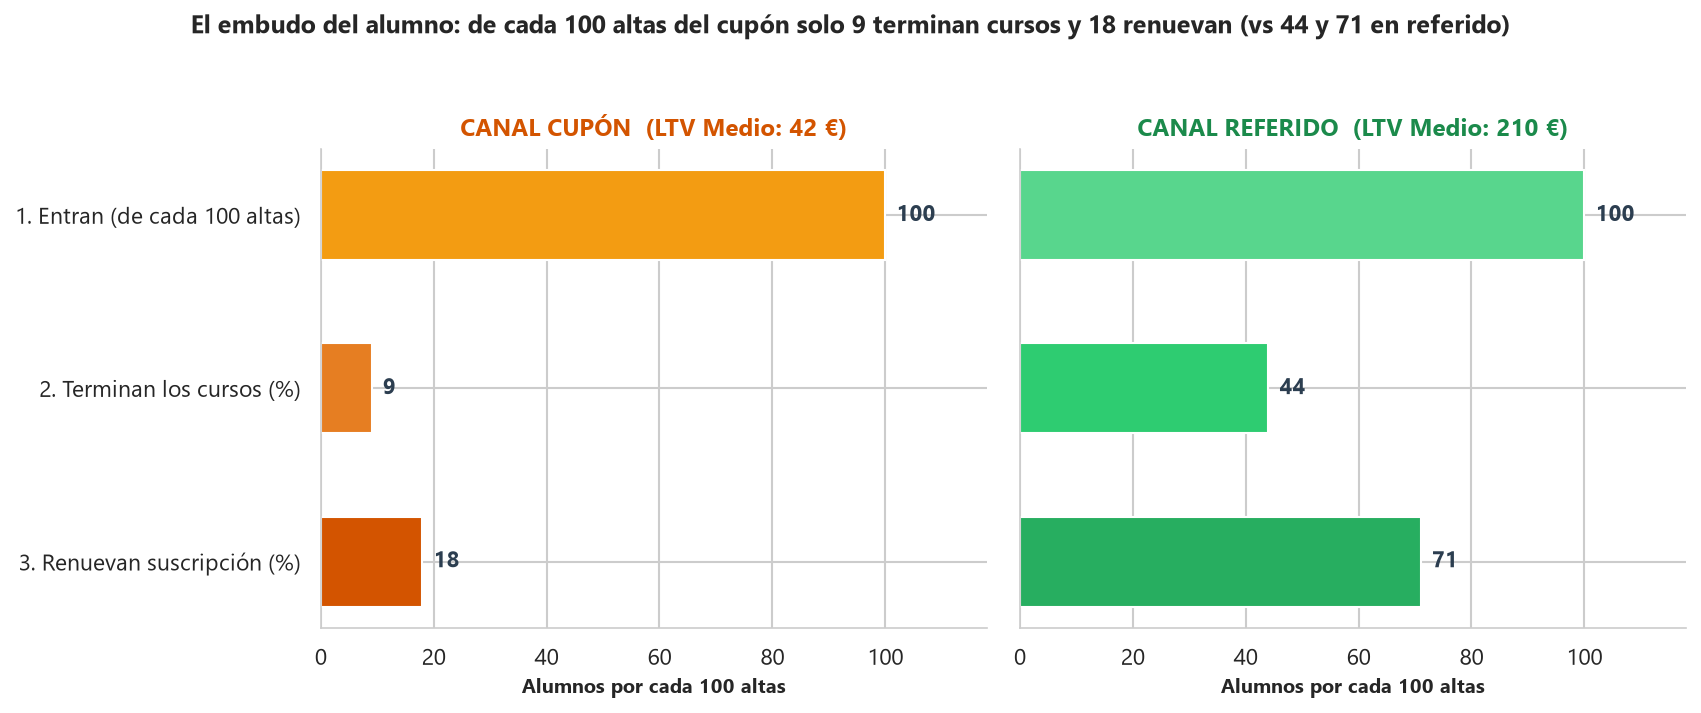

Guardado: reports\dia_05_grafico_3_embudo_cupon_vs_referido.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=150, sharey=True)

etapas = ['1. Entran (de cada 100 altas)', '2. Terminan los cursos (%)', '3. Renuevan suscripción (%)']
vals_cupon = [100, 9, 18]
vals_referido = [100, 44, 71]

# Panel Izquierdo: CUPÓN
b_c = axes[0].barh(etapas, vals_cupon, color=['#f39c12', '#e67e22', '#d35400'], height=0.52)
axes[0].set_xlim(0, 118)
axes[0].invert_yaxis()
axes[0].set_title('CANAL CUPÓN  (LTV Medio: 42 €)', fontsize=11.5, fontweight='bold', color='#d35400')
axes[0].set_xlabel('Alumnos por cada 100 altas', fontsize=9.5, fontweight='bold')
for bar in b_c:
    w = bar.get_width()
    axes[0].text(w + 2, bar.get_y() + bar.get_height()/2, f"{int(w)}", va='center', ha='left', fontsize=10.5, fontweight='bold', color='#2c3e50')
sns.despine(ax=axes[0], top=True, right=True)

# Panel Derecho: REFERIDO
b_r = axes[1].barh(etapas, vals_referido, color=['#58d68d', '#2ecc71', '#27ae60'], height=0.52)
axes[1].set_xlim(0, 118)
axes[1].set_title('CANAL REFERIDO  (LTV Medio: 210 €)', fontsize=11.5, fontweight='bold', color='#1b8a4b')
axes[1].set_xlabel('Alumnos por cada 100 altas', fontsize=9.5, fontweight='bold')
for bar in b_r:
    w = bar.get_width()
    axes[1].text(w + 2, bar.get_y() + bar.get_height()/2, f"{int(w)}", va='center', ha='left', fontsize=10.5, fontweight='bold', color='#2c3e50')
sns.despine(ax=axes[1], top=True, right=True)

fig.suptitle('El embudo del alumno: de cada 100 altas del cupón solo 9 terminan cursos y 18 renuevan (vs 44 y 71 en referido)', fontsize=11.8, fontweight='bold', y=1.03)
plt.tight_layout()

g3_path = os.path.join(REPORTS_DIR, 'dia_05_grafico_3_embudo_cupon_vs_referido.png')
plt.savefig(g3_path, dpi=150, bbox_inches='tight')
plt.show()
print("Guardado:", g3_path)


### 5. Gráfico 4 (EL QUE BLINDA): Control de Confusión por Categoría de Curso
Responde a la pregunta sobre la corazonada de Paula Rivas: dentro de cada una de las 6 categorías (desde `programacion` hasta `ofimatica`), la brecha entre `cupon` y `referido` es idéntica (~5x).


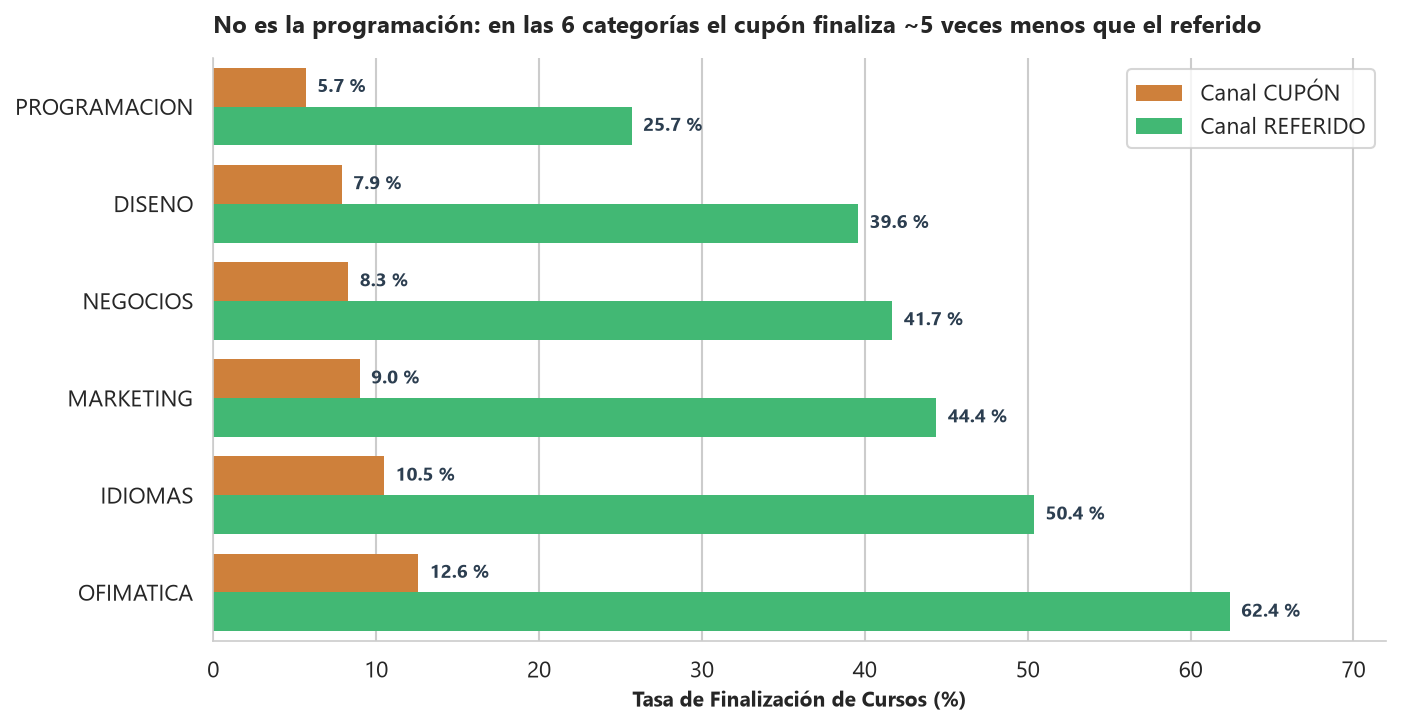

Guardado: reports\dia_05_grafico_4_control_confusion_categorias.png


In [6]:
q_cat = """
SELECT
    c.categoria,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'cupon' AND m.completado THEN 1 ELSE 0 END) / SUM(CASE WHEN u.canal = 'cupon' THEN 1 ELSE 0 END), 1) AS cupon_pct,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'referido' AND m.completado THEN 1 ELSE 0 END) / SUM(CASE WHEN u.canal = 'referido' THEN 1 ELSE 0 END), 1) AS referido_pct
FROM matriculas m
JOIN usuarios u ON m.usuario_id = u.usuario_id
JOIN cursos c ON m.curso_id = c.curso_id
GROUP BY c.categoria
ORDER BY cupon_pct ASC
"""
df_g4 = con.execute(q_cat).df()

fig, ax = plt.subplots(figsize=(9.5, 5.0), dpi=150)
df_g4_melt = df_g4.melt(id_vars='categoria', value_vars=['cupon_pct', 'referido_pct'], var_name='canal', value_name='finalizacion_pct')
df_g4_melt['canal'] = df_g4_melt['canal'].map({'cupon_pct': 'Canal CUPÓN', 'referido_pct': 'Canal REFERIDO'})
df_g4_melt['cat_label'] = df_g4_melt['categoria'].str.upper()

sns.barplot(
    data=df_g4_melt,
    x='finalizacion_pct',
    y='cat_label',
    hue='canal',
    palette={'Canal CUPÓN': '#e67e22', 'Canal REFERIDO': '#2ecc71'},
    ax=ax,
    edgecolor='none'
)

for container in ax.containers:
    for bar in container:
        w = bar.get_width()
        ax.text(w + 0.7, bar.get_y() + bar.get_height()/2, f"{w:.1f} %", va='center', ha='left', fontsize=9, fontweight='bold', color='#2c3e50')

ax.set_xlim(0, 72)
ax.set_xlabel('Tasa de Finalización de Cursos (%)', fontsize=10, fontweight='bold')
ax.set_ylabel('')
ax.set_title('No es la programación: en las 6 categorías el cupón finaliza ~5 veces menos que el referido', fontsize=11.5, fontweight='bold', loc='left', pad=12)
ax.legend(title='', loc='upper right', frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()

g4_path = os.path.join(REPORTS_DIR, 'dia_05_grafico_4_control_confusion_categorias.png')
plt.savefig(g4_path, dpi=150)
plt.show()
print("Guardado:", g4_path)


### 6. El One-Pager Ejecutivo (`reports/ONE_PAGER.md`) y las 4 Preguntas del Comité
El informe ejecutivo completo siguiendo la estructura de pirámide invertida ha sido generado en `reports/ONE_PAGER.md`.

**Escudo de respuestas rápidas para la reunión de 20 minutos con Elena, Diego y Paula:**
1. **Diego (*«¿Pero el cupón no era el más barato por alta?»*):**
   * *Respuesta:* «Sí, sigue siéndolo con `6 €` de CAC y `38 %` de las altas. El problema es lo que pasa después del alta: como sus alumnos entran por el descuento, solo renueva el `18 %` y dejan `42 €` de media, por lo que apenas aportan el `15 %` del valor total de AulaViva.»
2. **Elena (*«¿Y eso en valor por alumno y en mi presupuesto de 300.000 € cuánto es?»*):**
   * *Respuesta:* «Un alumno de cupón deja `42 €` de LTV (~3 meses); uno de referido deja `210 €` (~14 meses, 5 veces más). Meter `300.000 €` en el cupón compraría `50.000` altas de las que `41.050` se dan de baja sin renovar; invertirlos en referido compra alumnos que se quedan y multiplica por tres el valor generado a largo plazo.»
3. **Paula (*«¿No será que el cupón lleva gente a programación, que es más difícil?»*):**
   * *Respuesta:* «Lo comprobamos con un control por categoría: primero, el cupón reparte sus matrículas igual que el resto (`16,5 %` en programación). Segundo, dentro de programación el cupón finaliza el `5,7 %` frente al `25,7 %` del referido, y en ofimática (la más fácil) el `12,6 %` frente al `62,4 %`. La categoría mueve el nivel general, pero la brecha viaja siempre con el canal.»
4. **Rigor técnico (*«¿Estás seguro de que los datos están bien?»*):**
   * *Respuesta:* «Sí: deduplicamos los `1.360` cobros repetidos del webhook de Stripe, conservamos las `14.255` altas sin campaña de SEO y referido mediante `LEFT JOIN`, y tratamos las `17.278` suscripciones sin `fecha_fin` como lo que son: alumnos activos que siguen pagando. Si hubiéramos hecho mal cualquiera de las tres, el ranking se invertiría.»
5. **Cerrar el círculo (De SQL a Looker):**
   * *Recomendación final:* Incorporar al panel diario de Looker las tres métricas validadas (**Tasa de Finalización**, **Tasa de Renovación** y **LTV / Cuota de Valor por canal**) junto a las altas y el CAC para que Growth no vuelva a dirigir a ciegas.
